In [276]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,KFold,cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

test = pd.read_csv('../data/raw/test.csv')
train = pd.read_csv('../data/raw/train.csv')


In [299]:
train_processed = train.copy()
test_processed = test.copy()
train_processed.to_csv('../data/processed/train_processed.csv',index=False)
test_processed.to_csv('../data/processed/test_processed.csv',index=False)

In [278]:
print(train.shape)
print(train.info())
train.describe()

(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [279]:
print(test.shape)
print(test.info())
test.describe()

(1459, 80)
<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   str    
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   Alley          107 non-null    str    
 7   LotShape       1459 non-null   str    
 8   LandContour    1459 non-null   str    
 9   Utilities      1457 non-null   str    
 10  LotConfig      1459 non-null   str    
 11  LandSlope      1459 non-null   str    
 12  Neighborhood   1459 non-null   str    
 13  Condition1     1459 non-null   str    
 14  Condition2     1459 non-null   str    
 15  BldgType       1459 non-null   str    
 16  HouseStyle     1459 non-null   str    
 17  OverallQual    1459 non-null   int64  
 18  OverallC

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
count,1459.000000,1459.000000,1232.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1444.000000,1458.000000,...,1458.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000
mean,2190.000000,57.378341,68.580357,9819.161069,6.078821,5.553804,1971.357779,1983.662783,100.709141,439.203704,...,472.768861,93.174777,48.313914,24.243317,1.794380,17.064428,1.744345,58.167923,6.104181,2007.769705
std,421.321334,42.746880,22.376841,4955.517327,1.436812,1.113740,30.390071,21.130467,177.625900,455.268042,...,217.048611,127.744882,68.883364,67.227765,20.207842,56.609763,30.491646,630.806978,2.722432,1.301740
min,1461.000000,20.000000,21.000000,1470.000000,1.000000,1.000000,1879.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000
25%,1825.500000,20.000000,58.000000,7391.000000,5.000000,5.000000,1953.000000,1963.000000,0.000000,0.000000,...,318.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000
50%,2190.000000,50.000000,67.000000,9399.000000,6.000000,5.000000,1973.000000,1992.000000,0.000000,350.500000,...,480.000000,0.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000
75%,2554.500000,70.000000,80.000000,11517.500000,7.000000,6.000000,2001.000000,2004.000000,164.000000,753.500000,...,576.000000,168.000000,72.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000
max,2919.000000,190.000000,200.000000,56600.000000,10.000000,9.000000,2010.000000,2010.000000,1290.000000,4010.000000,...,1488.000000,1424.000000,742.000000,1012.000000,360.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000


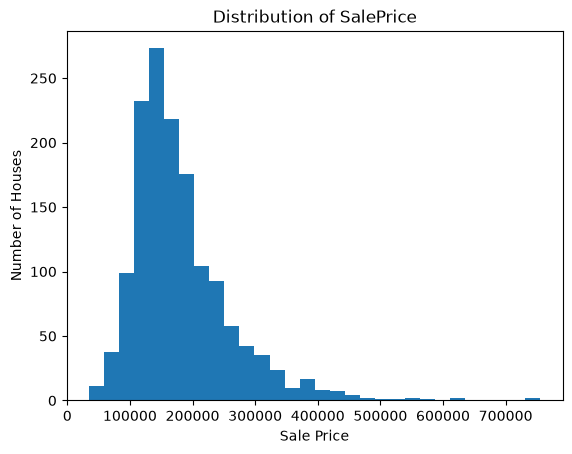

In [280]:
plt.hist(train['SalePrice'], bins=30)
plt.xlabel('Sale Price')
plt.ylabel('Number of Houses')
plt.title('Distribution of SalePrice')
plt.show()

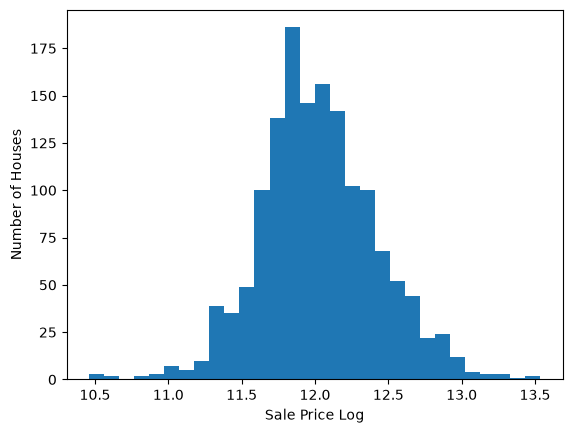

In [281]:
plt.hist(np.log(train['SalePrice']),bins = 30)
plt.xlabel('Sale Price Log')
plt.ylabel('Number of Houses')
plt.show()

In [301]:
missing_train = train.isna().sum()
missing_train = missing_train[missing_train != 0]
missing_test = test.isna().sum()
missing_test = missing_test[missing_test != 0]

lot_median = train['LotFrontage'].median()

train_processed['LotFrontage'] = train['LotFrontage'].fillna(lot_median)
test_processed['LotFrontage'] = test['LotFrontage'].fillna(lot_median)

mode_columns = ['MSZoning','Electrical','KitchenQual','Exterior1st','Exterior2nd','SaleType','Functional','Utilities']
none_columns = ['Alley','MasVnrType','BsmtCond','BsmtQual','BsmtExposure','BsmtFinType1','BsmtFinType2','FireplaceQu','GarageType','GarageFinish','GarageQual','GarageCond','PoolQC','Fence','MiscFeature']
zero_columns = ['MasVnrArea','GarageYrBlt','GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath']
for i in mode_columns:
    mode = train[i].mode()[0]
    train_processed[i] = train_processed[i].fillna(mode)
    test_processed[i] = test_processed[i].fillna(mode)
for i in none_columns:
    train_processed[i] = train_processed[i].fillna('None')
    test_processed[i] = test_processed[i].fillna('None')
for i in zero_columns:
    train_processed[i] = train_processed[i].fillna(0)
    test_processed[i] = test_processed[i].fillna(0)
print("Train missing values:")
print(train_processed.isna().sum()[train_processed.isna().sum() > 0])

print("Test missing values:")
print(test_processed.isna().sum()[test_processed.isna().sum() > 0])


Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


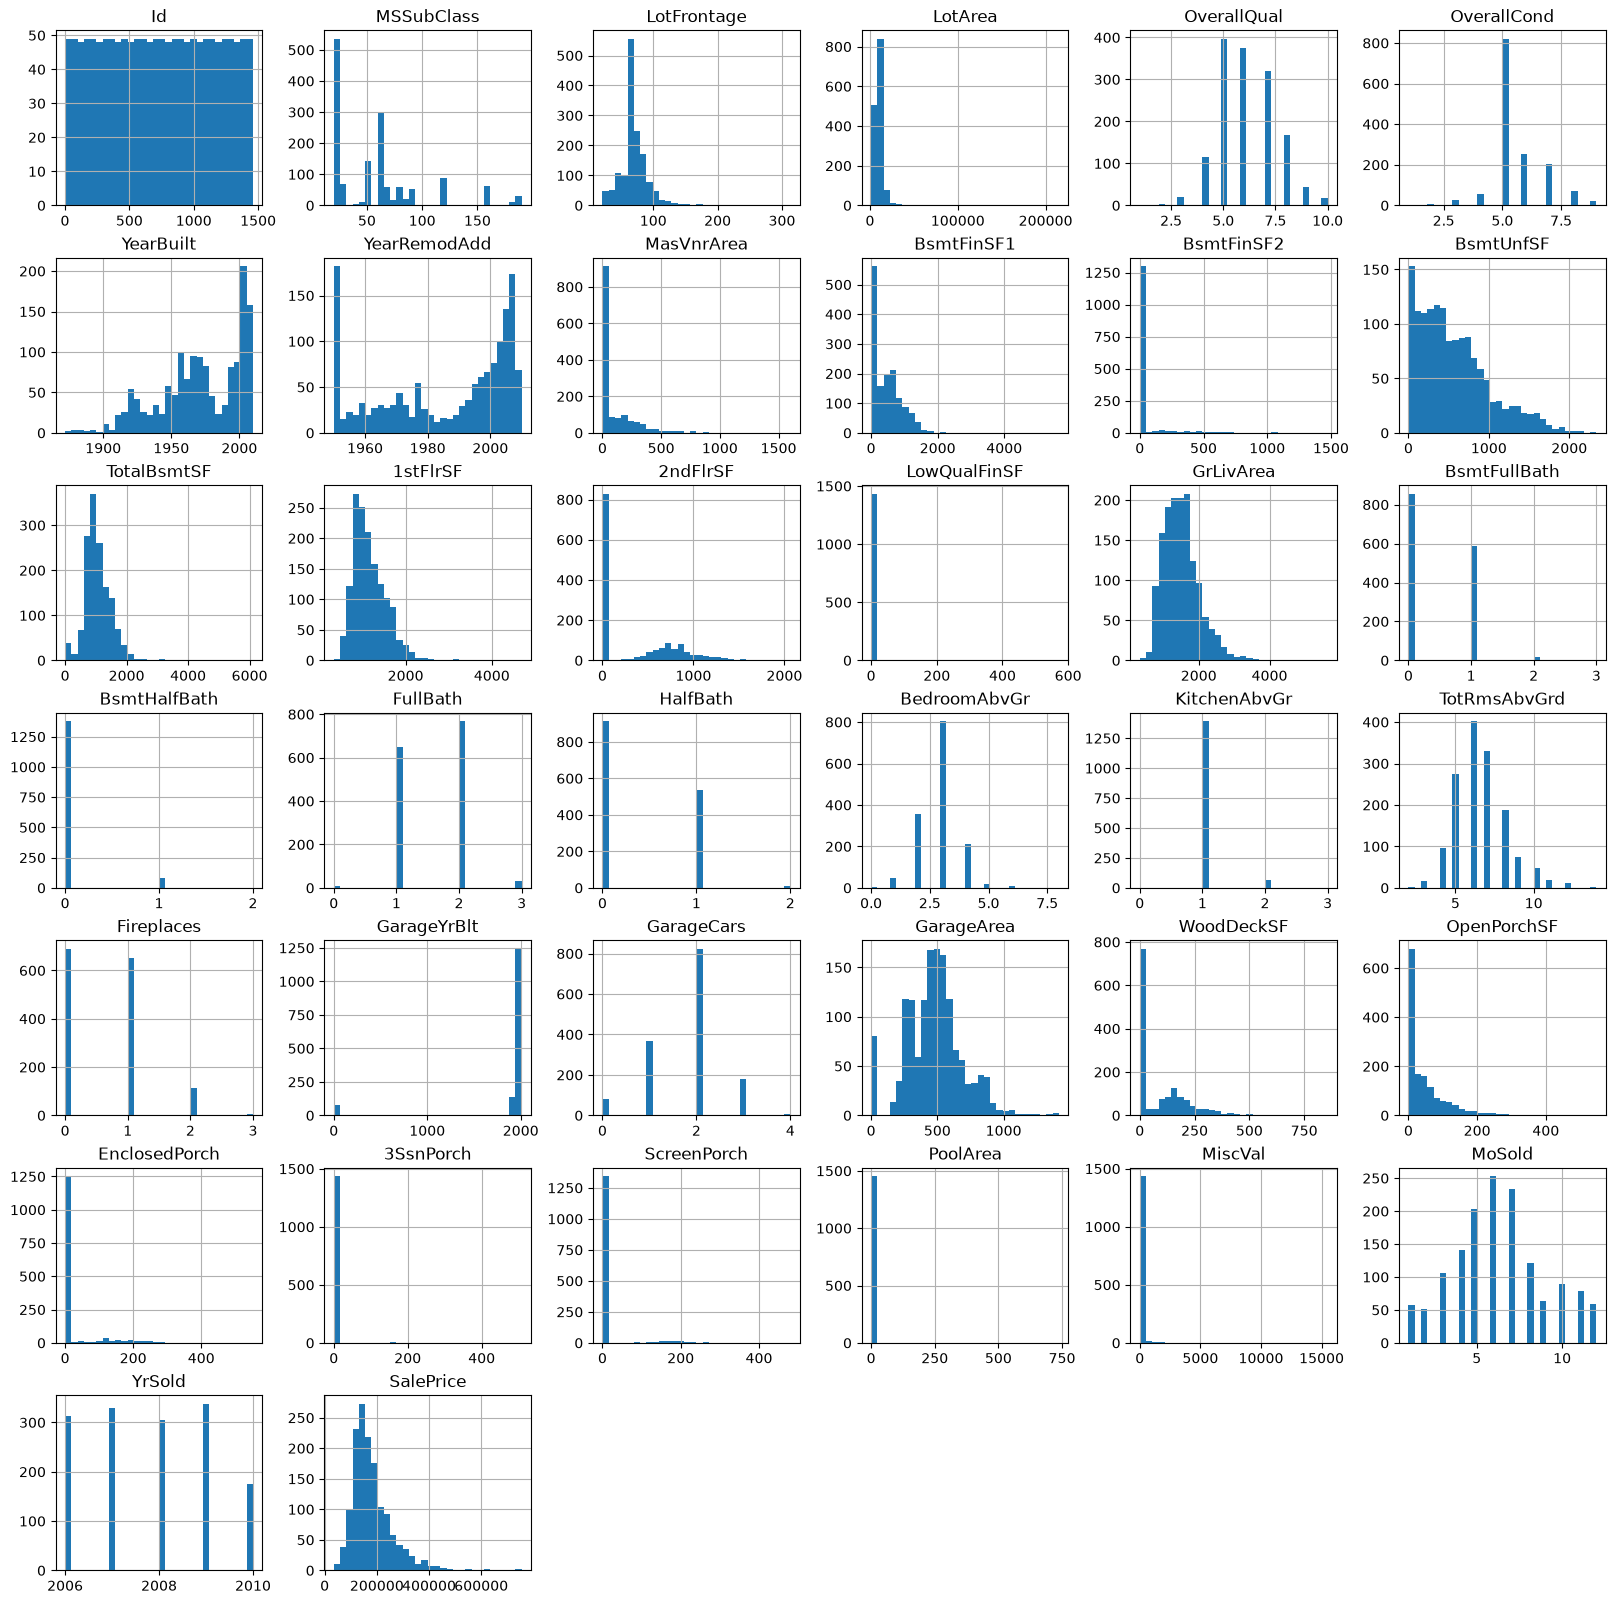

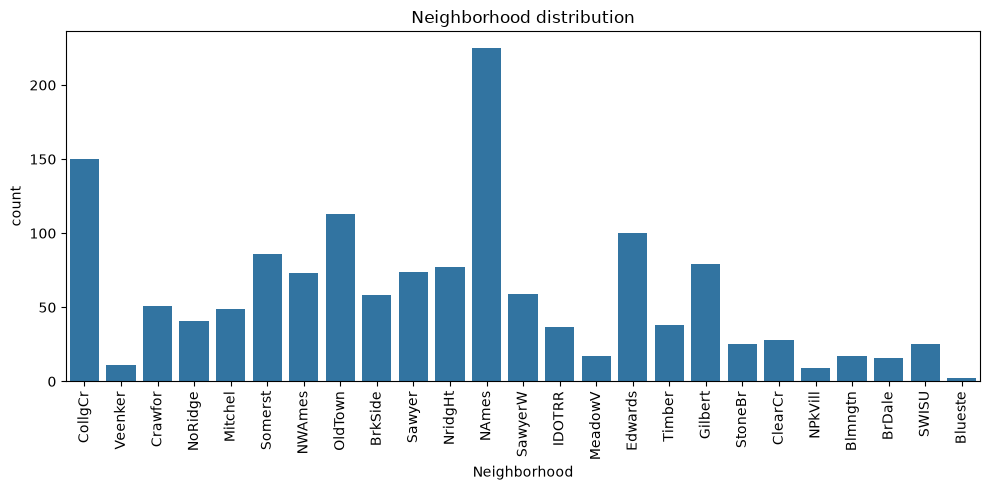

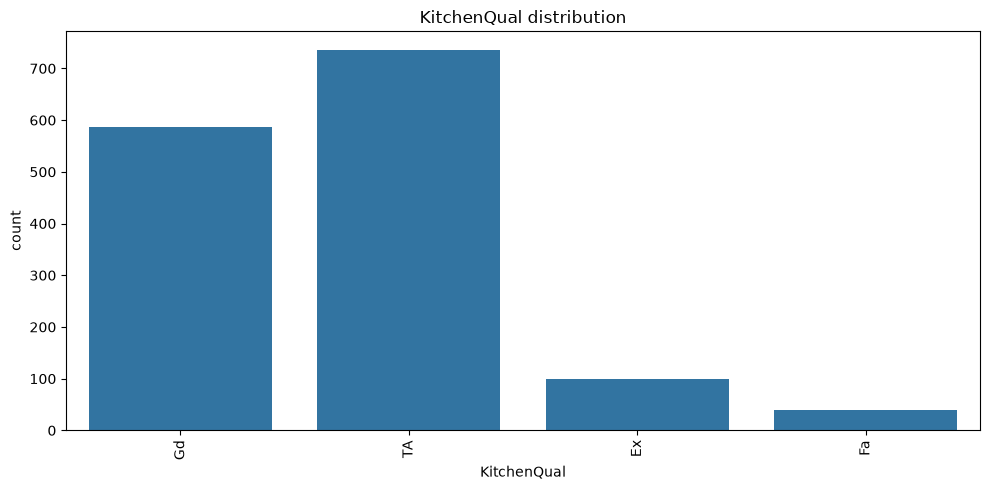

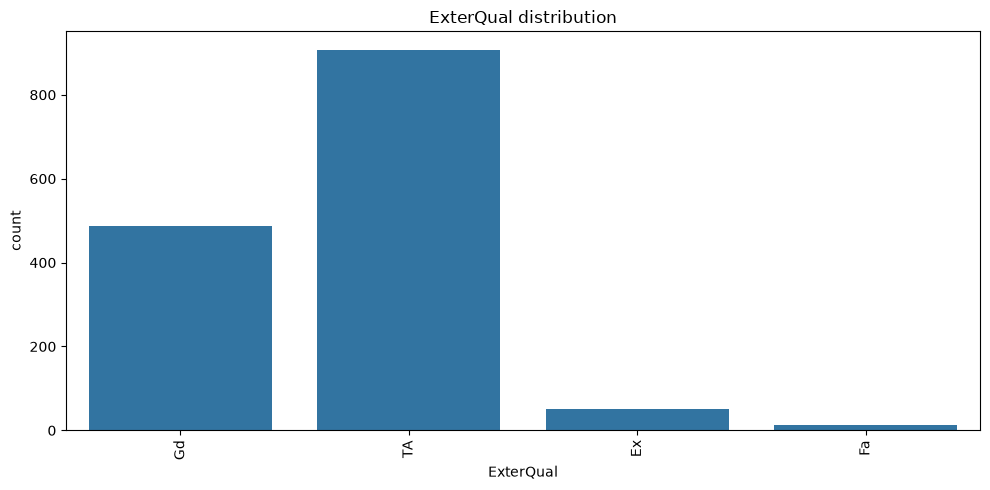

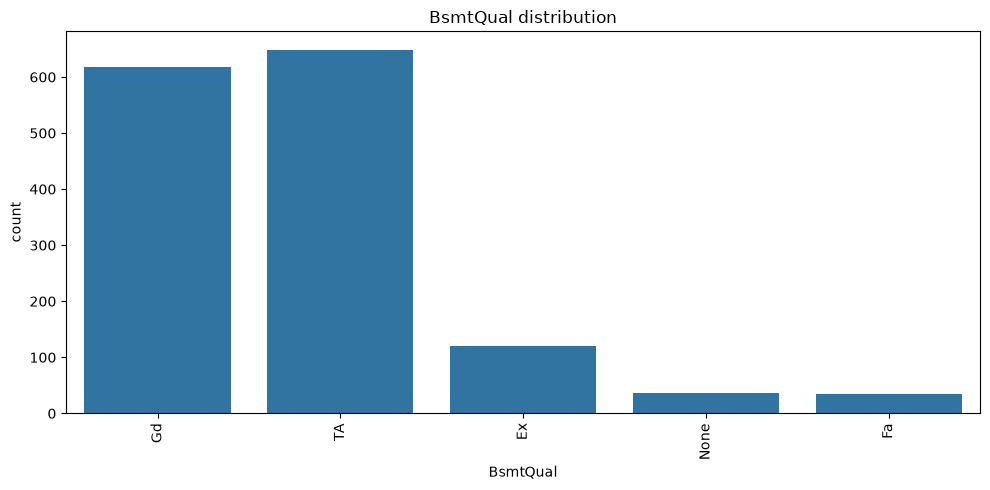

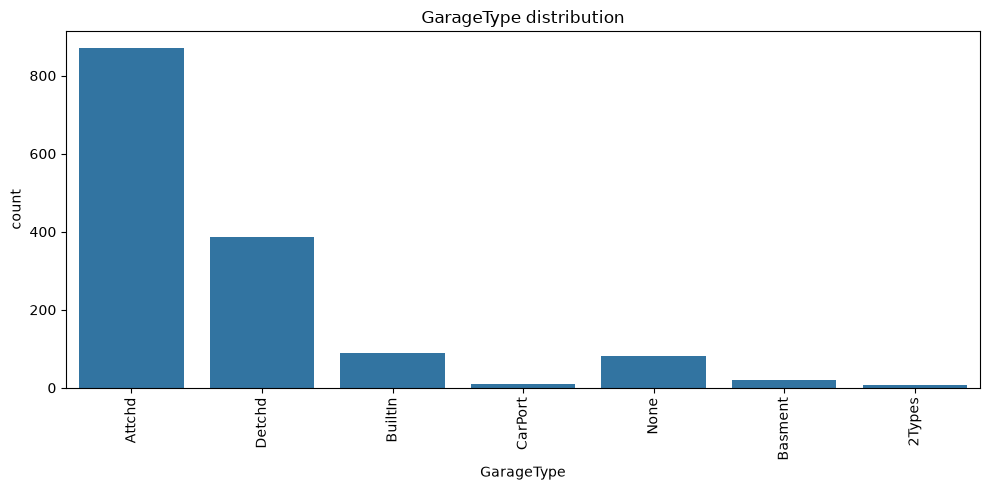

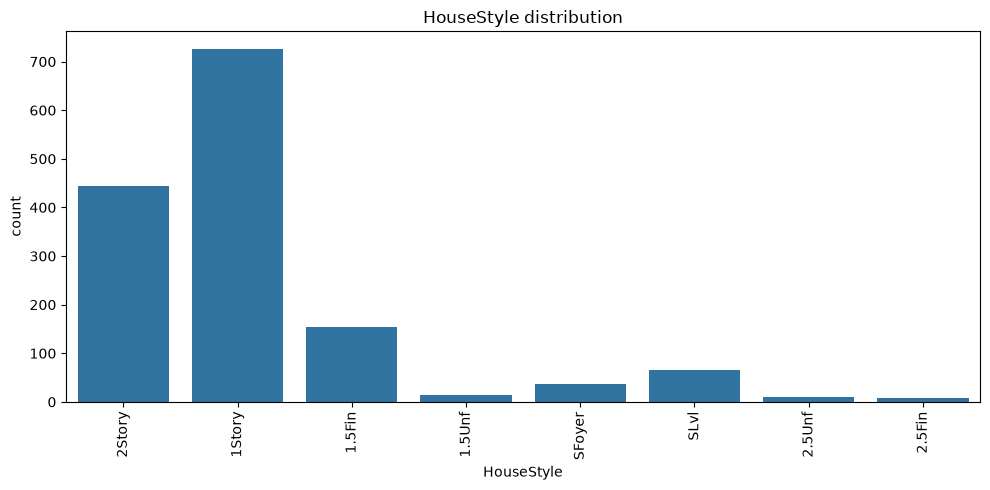

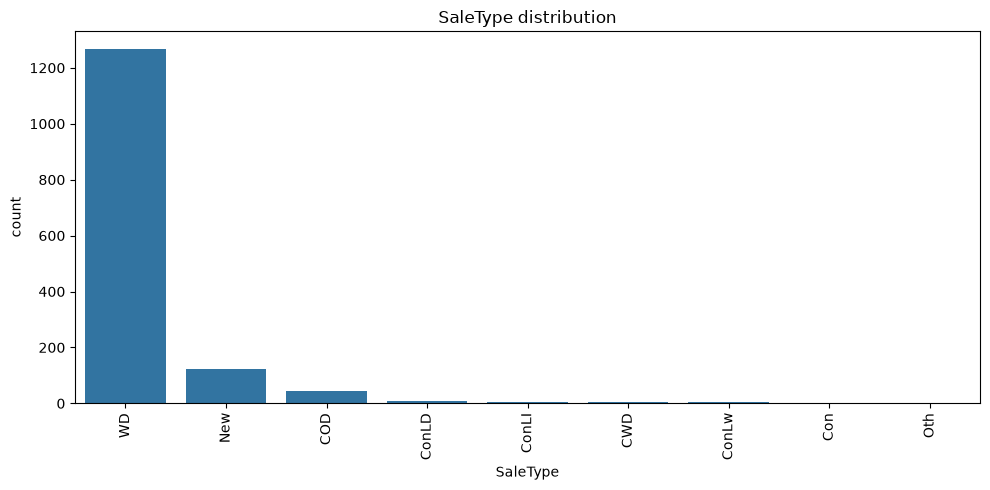

Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


In [ ]:
num_columns = train_processed.select_dtypes(include=['number']).columns
train_processed[num_columns].hist(figsize=(20, 20), bins=30)
plt.show()



plot_cat_cols = ['Neighborhood','KitchenQual','ExterQual','BsmtQual','GarageType','HouseStyle','SaleType']
for i in plot_cat_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=train_processed,
        x=i
    )

    plt.xticks(rotation=90)
    plt.title(f'{i} distribution')
    plt.tight_layout()
    plt.show()


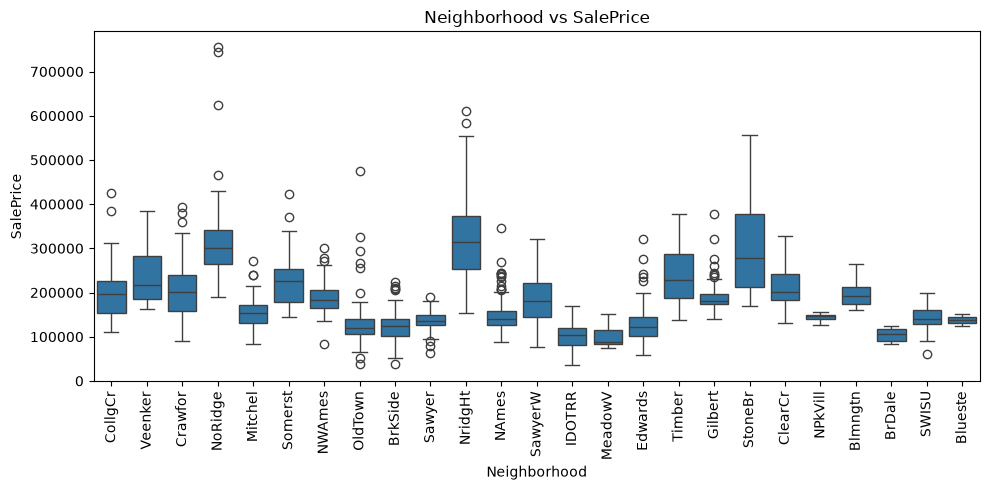

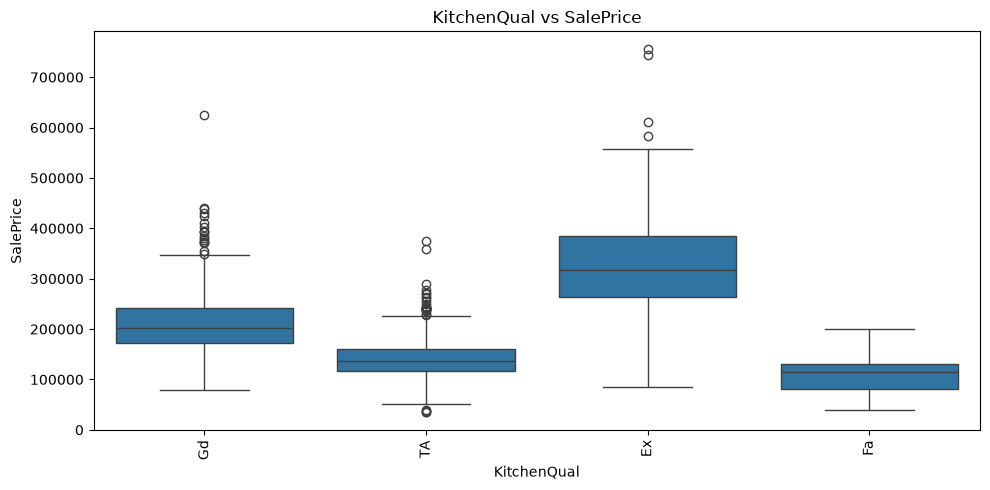

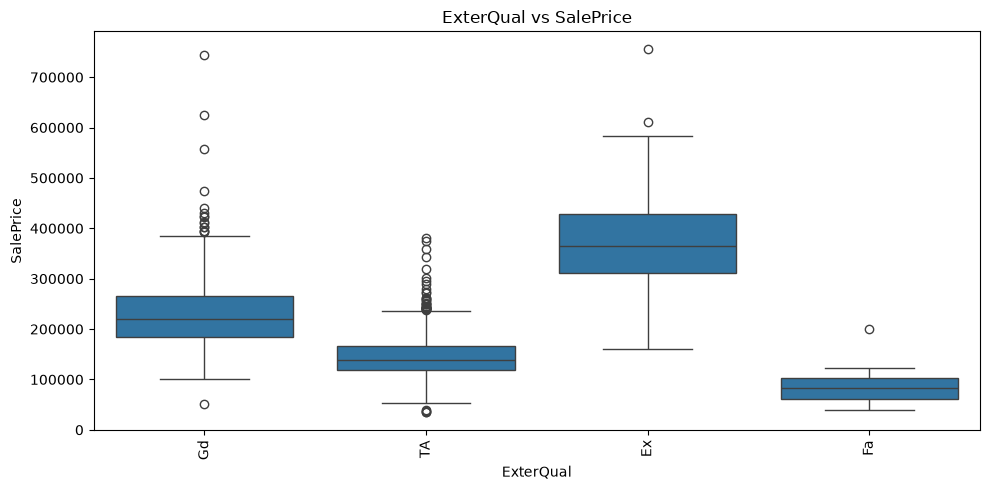

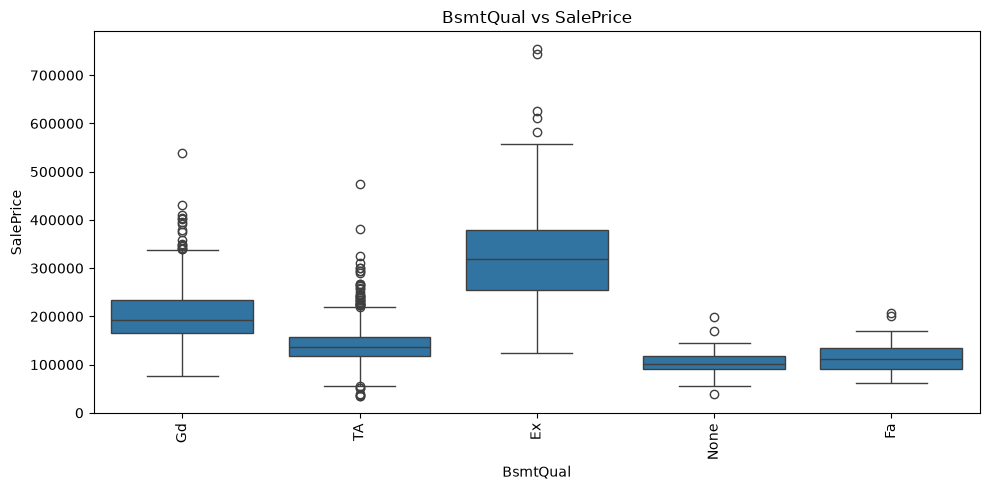

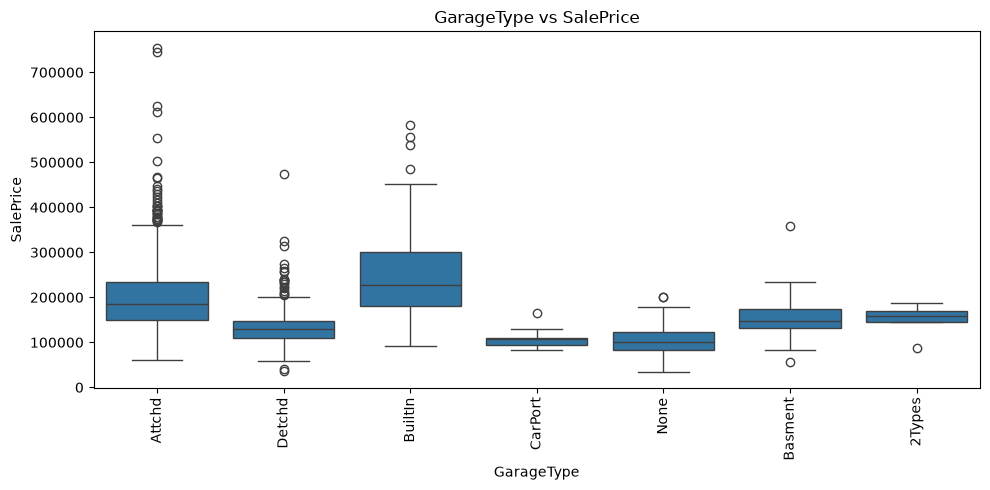

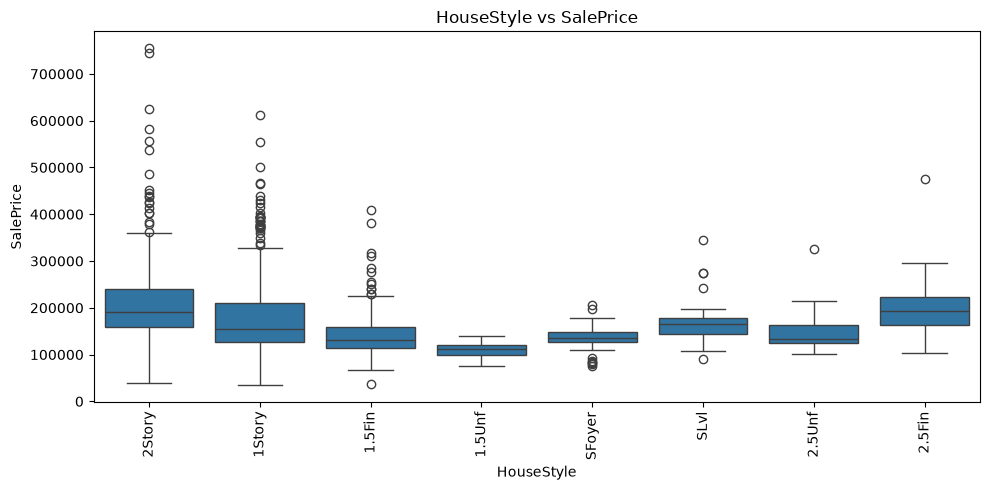

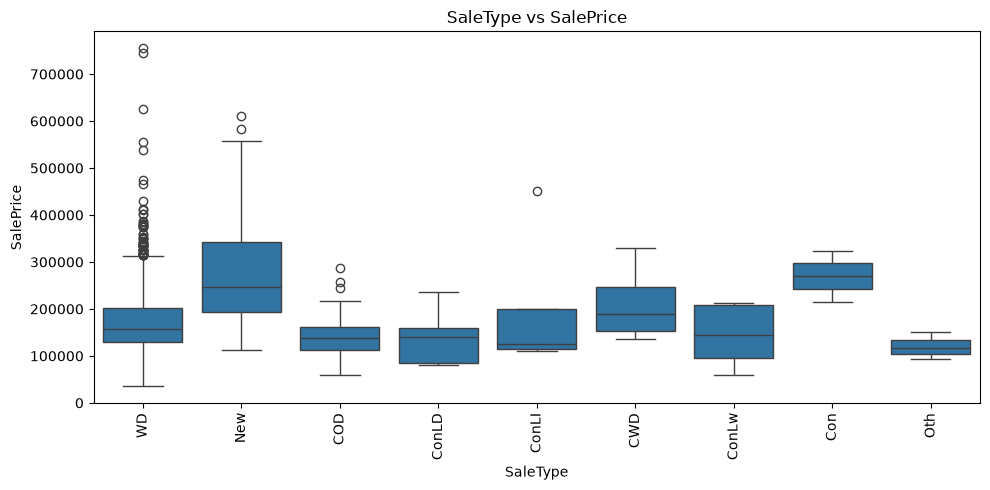

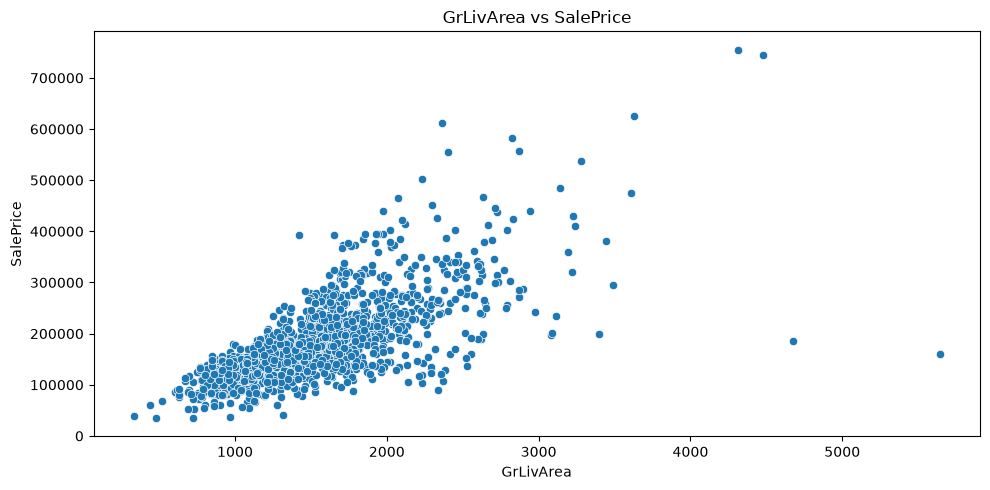

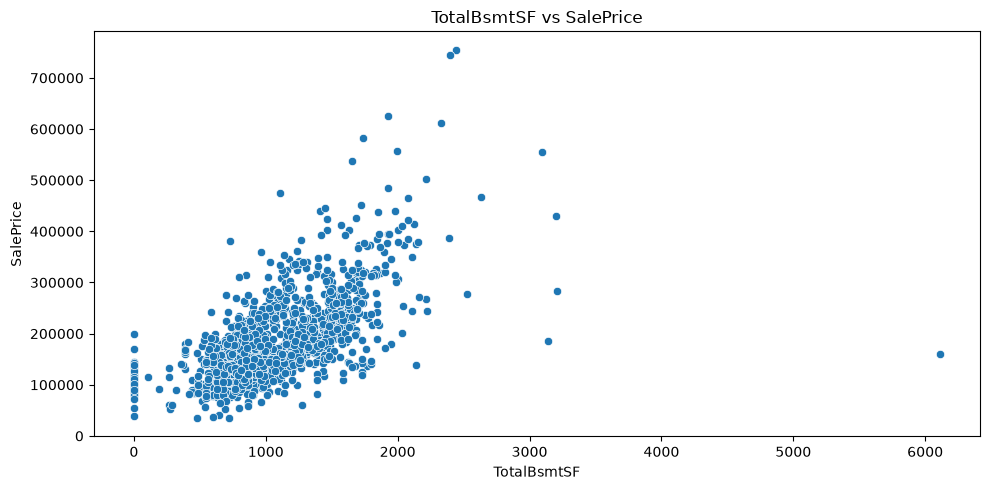

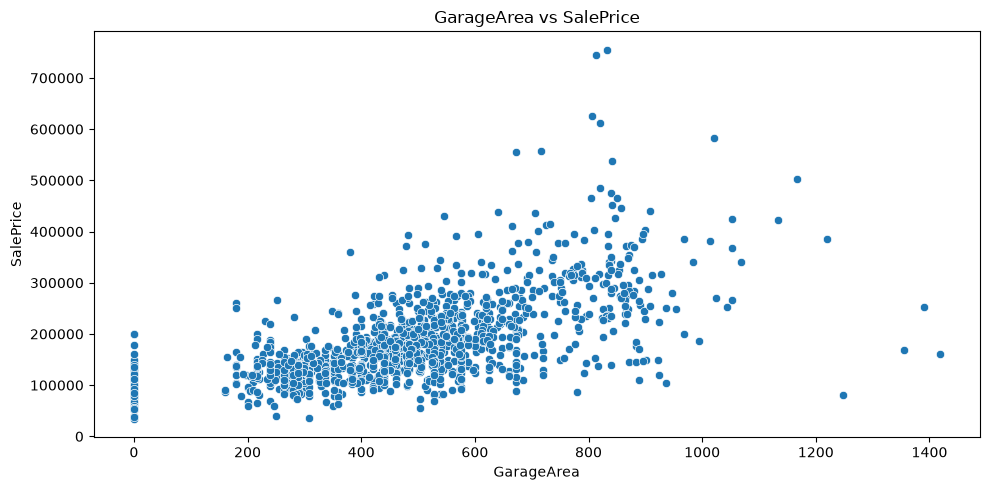

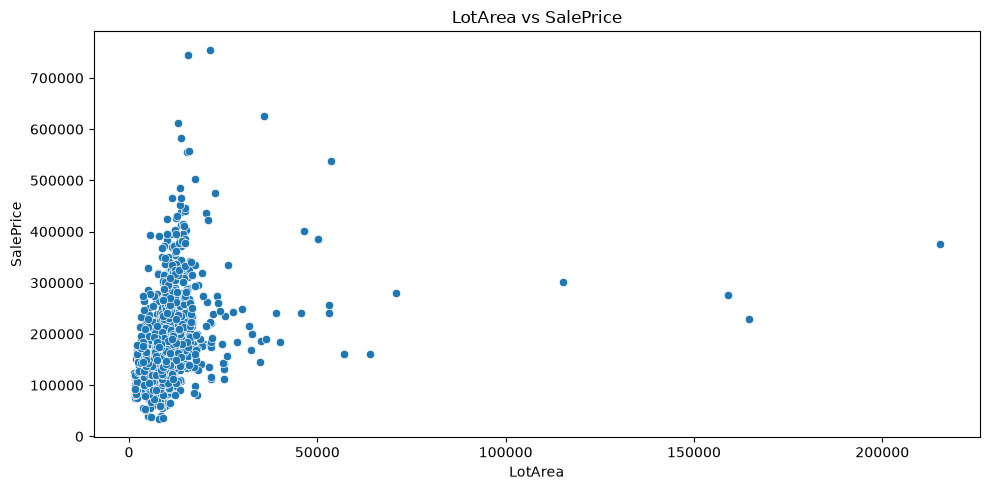

In [284]:
for i in plot_cat_cols:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=train_processed,
        x=i,
        y='SalePrice'
    )

    plt.xticks(rotation=90)
    plt.title(f'{i} vs SalePrice')
    plt.tight_layout()
    plt.show()
    
scatter_cols = ['GrLivArea','TotalBsmtSF','GarageArea','LotArea']
for i in scatter_cols:
    plt.figure(figsize=(10, 5))

    sns.scatterplot(
        data=train_processed,
        x=i,
        y='SalePrice'
    )

    plt.title(f'{i} vs SalePrice')
    plt.tight_layout()
    plt.show()

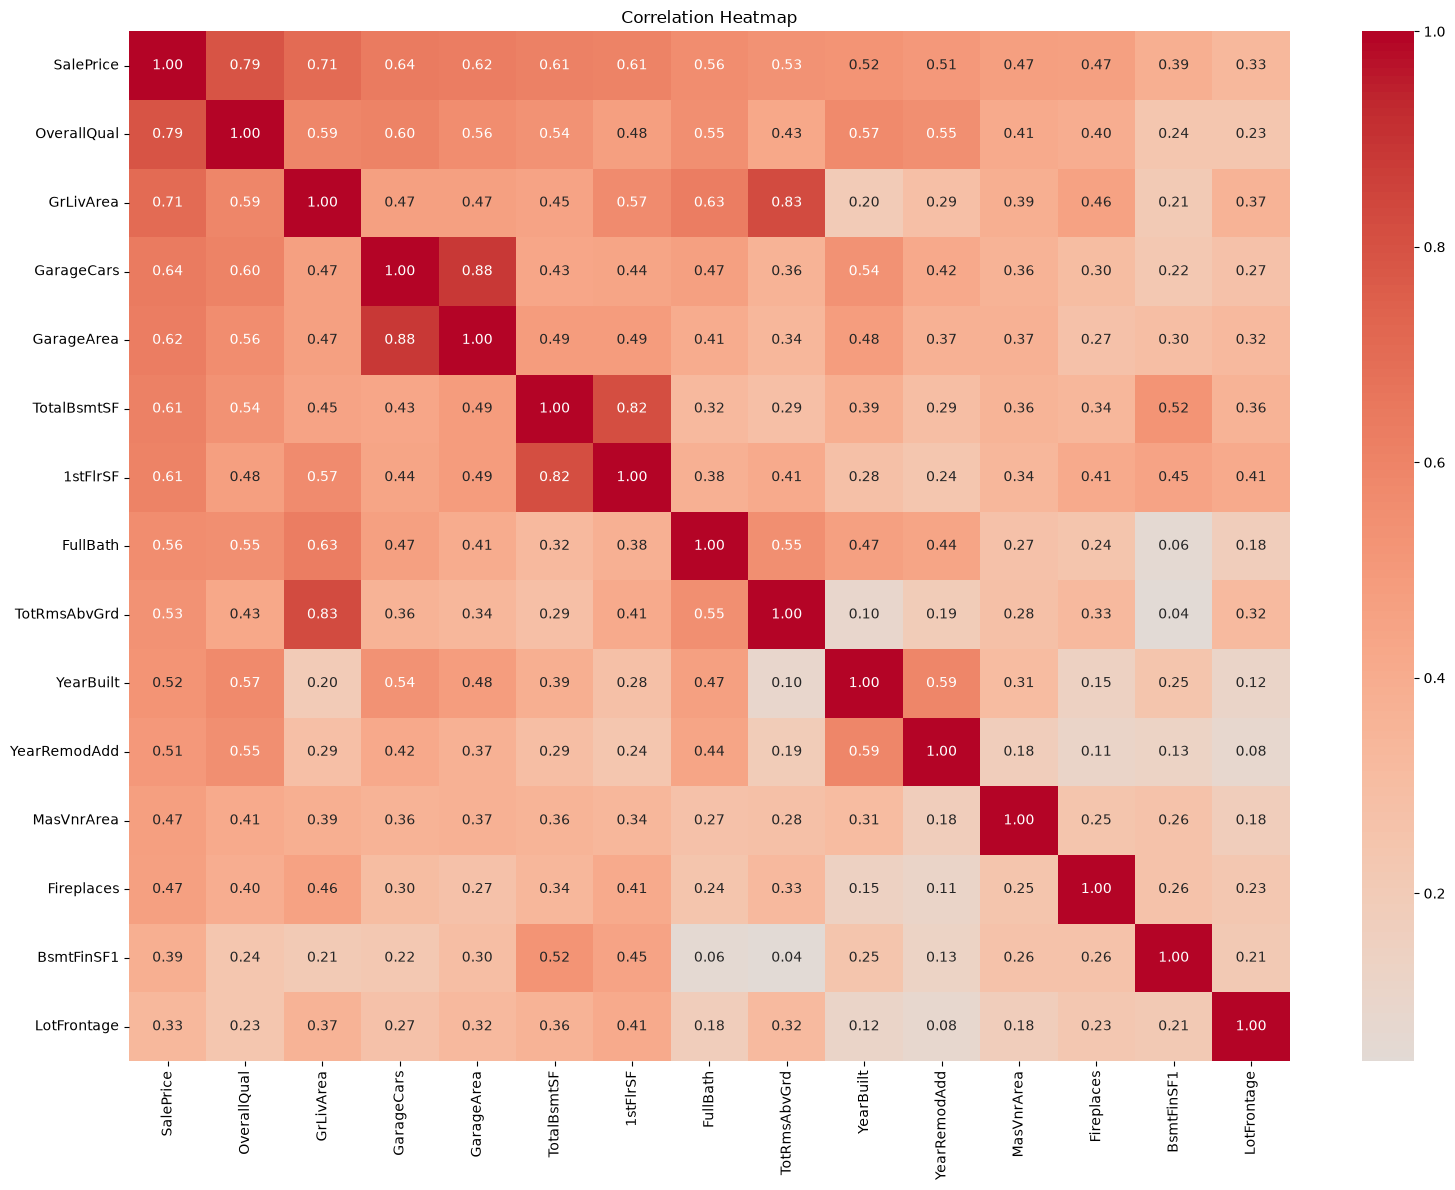

In [285]:
num_data = train_processed.select_dtypes(include="number")
correlations = num_data.corr()['SalePrice'].abs().sort_values(ascending=False)

top_features = correlations.head(15).index


plt.figure(figsize=(16, 12))

sns.heatmap(
    num_data[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

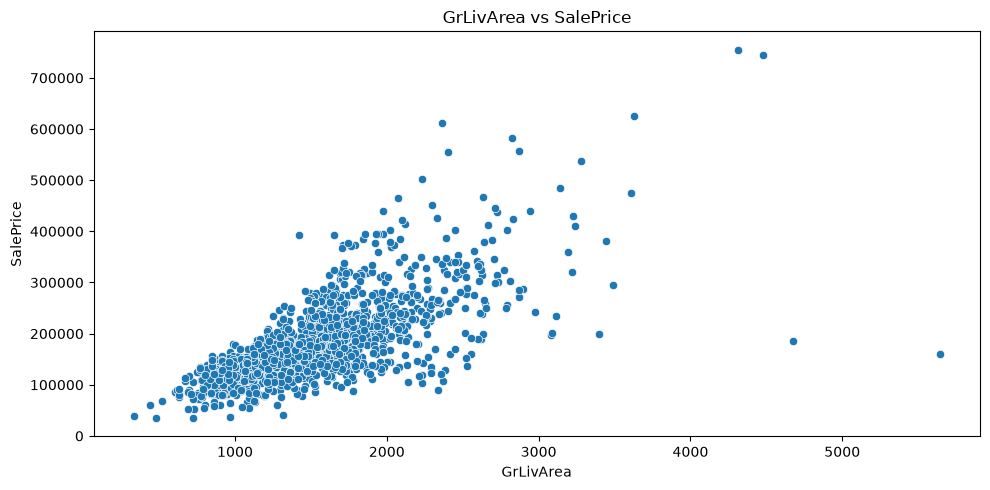

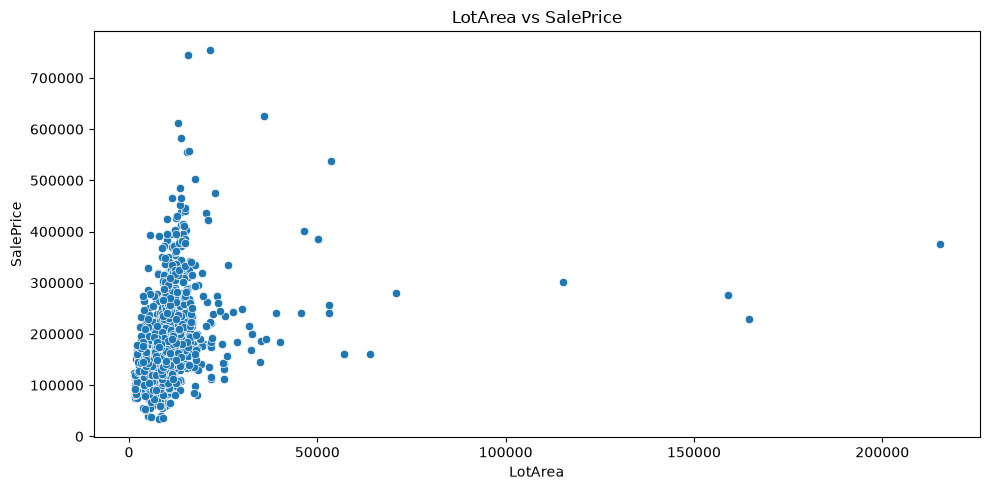

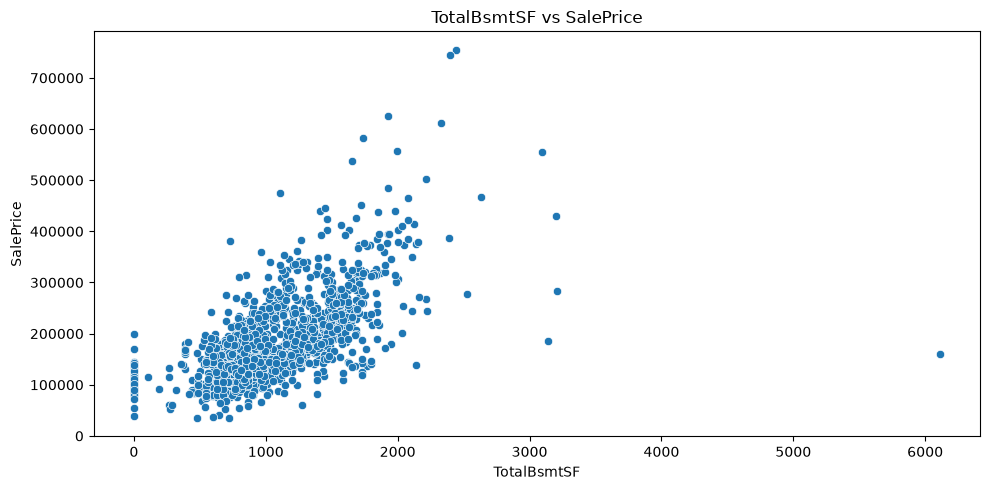

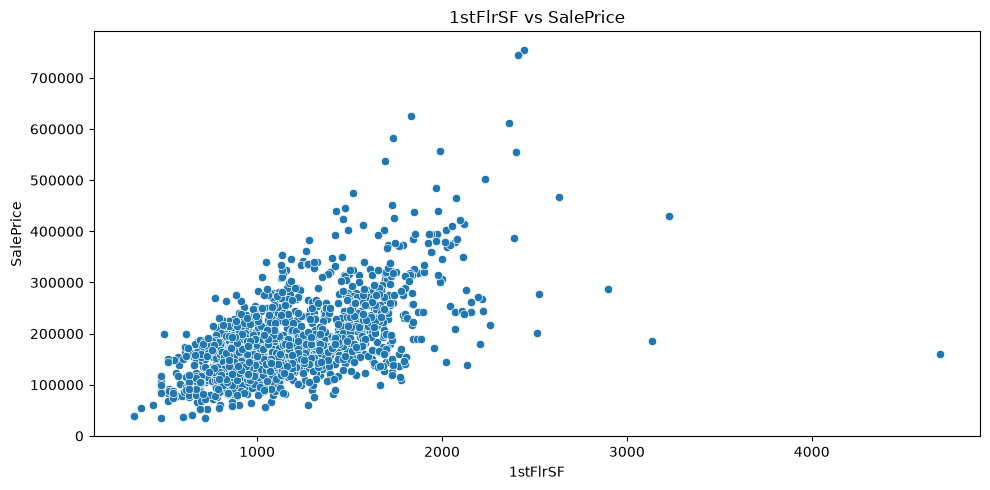

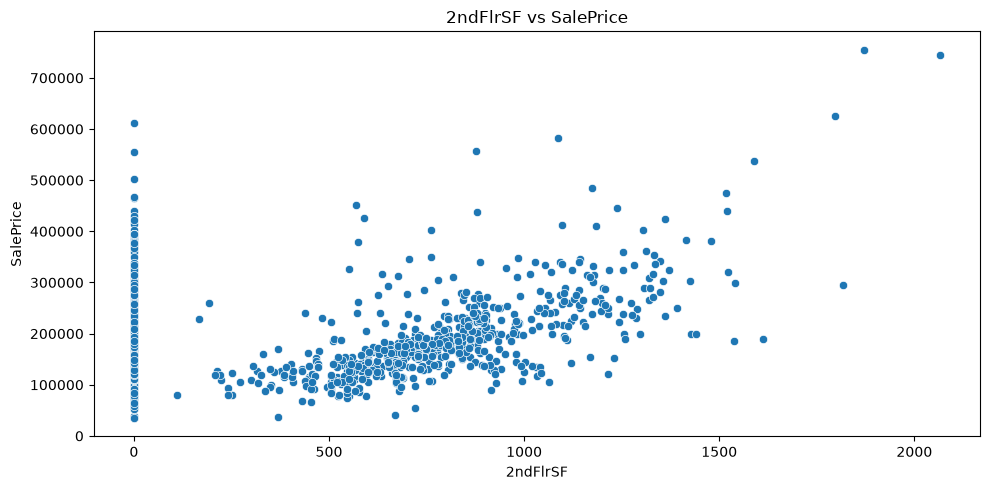

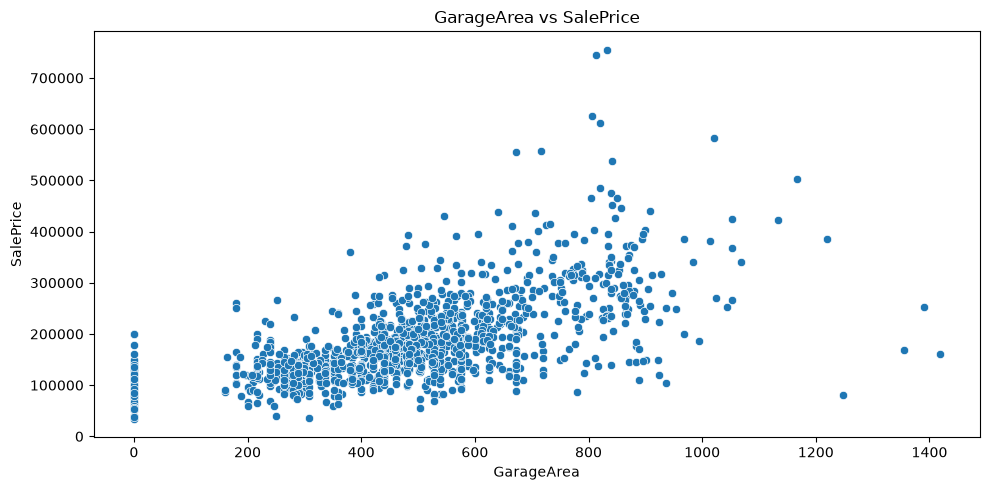

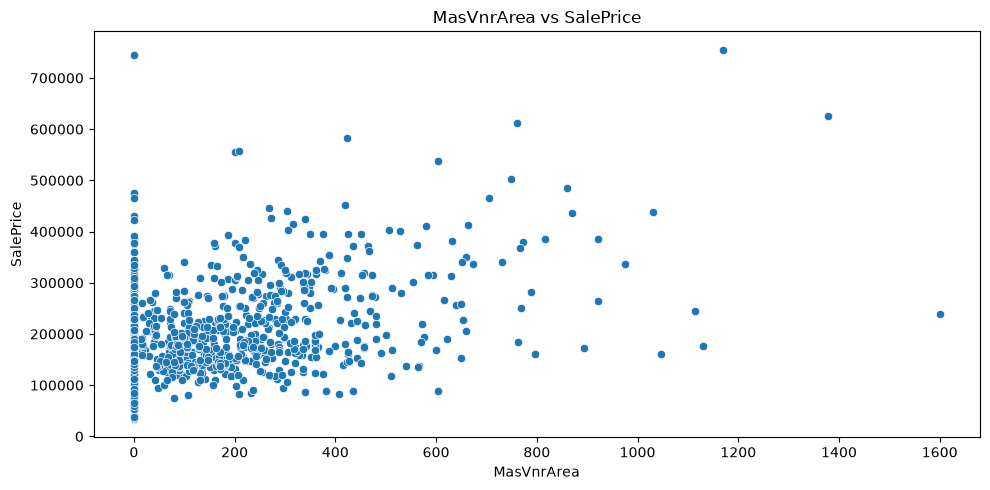

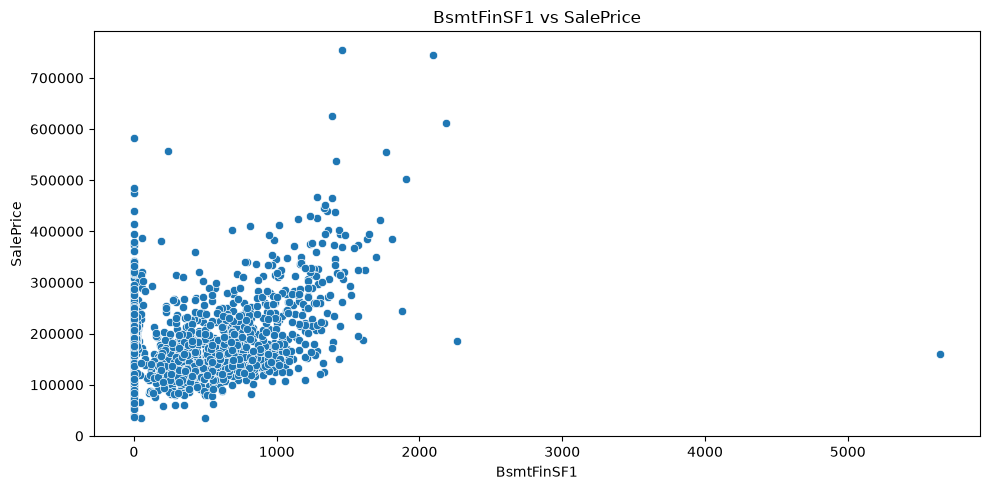

GrLivArea: 31 outliers
LotArea: 69 outliers
TotalBsmtSF: 61 outliers
1stFlrSF: 20 outliers
2ndFlrSF: 2 outliers
GarageArea: 21 outliers
MasVnrArea: 98 outliers
BsmtFinSF1: 7 outliers
Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


In [ ]:
def is_iqr_outlier(column):
    q1,q3 = column.quantile([.25,.75])
    iqr = q3 - q1
    return (column < q1 - 1.5 * iqr) | (column > q3 + 1.5 * iqr)
features = [
    'GrLivArea',
    'LotArea',
    'TotalBsmtSF',
    '1stFlrSF',
    '2ndFlrSF',
    'GarageArea',
    'MasVnrArea',
    'BsmtFinSF1'
]
for i in features:
    plt.figure(figsize= (10,5))
    sns.scatterplot(data=train_processed,x=i,y='SalePrice')
    plt.title(f'{i} vs SalePrice')
    plt.tight_layout()
    plt.show()
for i in features:
    outlier_bool = is_iqr_outlier(train_processed[i])
    print(f"{i}: {outlier_bool.sum()} outliers")     
grLiveArea_outliers = train_processed[(train_processed['GrLivArea'] > 4000) &(train_processed['SalePrice'] < 300000)]
train_processed = train_processed.drop(grLiveArea_outliers.index)

In [ ]:
train_processed['TotalSF'] = train_processed['TotalBsmtSF'] + train_processed['1stFlrSF'] + train_processed['2ndFlrSF']
test_processed['TotalSF'] = test_processed['TotalBsmtSF'] + test_processed['1stFlrSF'] + test_processed['2ndFlrSF']

train_processed['HouseAge'] = train_processed['YrSold'] - train_processed['YearBuilt']
test_processed['HouseAge'] = test_processed['YrSold'] - test_processed['YearBuilt']

train_processed['RemodAge'] = train_processed['YrSold'] - train_processed['YearRemodAdd']
test_processed['RemodAge'] = test_processed['YrSold'] - test_processed['YearRemodAdd']

train_processed['TotalRooms'] = train_processed['TotRmsAbvGrd'] + train_processed['FullBath'] + train_processed['HalfBath']
test_processed['TotalRooms'] = test_processed['TotRmsAbvGrd'] + test_processed['FullBath'] + test_processed['HalfBath']


# X_old = train_processed.drop(columns=['SalePrice','Id','TotalSF','HouseAge','RemodAge'])
# X_new = train_processed.drop(columns=['SalePrice','Id'])
# y = train_processed['SalePrice']

# X_old_train,X_old_val,y_old_train,y_old_val = train_test_split(X_old,y,test_size=0.2,random_state=42)
# X_new_train,X_new_val,y_new_train,y_new_val = train_test_split(X_new,y,test_size=0.2,random_state=42)

# model_old = RandomForestRegressor(n_estimators=100,random_state=42)
# model_new = RandomForestRegressor(n_estimators=100,random_state=42)
# model_old.fit(X_old_train,y_old_train)
# model_new.fit(X_new_train,y_new_train)

# pred_old = model_old.predict(X_old_val)
# pred_new = model_old.predict(X_new_val)

# rmse_old = root_mean_squared_error(np.log(y_old_val),np.log(pred_old))
# rmse_new = root_mean_squared_error(np.log(y_new_val),np.log(pred_new))
# print(f"{rmse_old} Old rmse")
# print(f"{rmse_new} Old rmse")


Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


In [ ]:
plt.figure(figsize=(10, 5))
# sns.countplot(data= train_processed,x='Street')
# plt.tight_layout()
# plt.show()
# sns.countplot(data= train_processed,x='Utilities')
# plt.tight_layout()
# plt.show()
# train_processed['Utilities'].value_counts()
# train_processed['Street'].value_counts()

train_processed = train_processed.drop(columns=["Utilities"])
test_processed = test_processed.drop(columns=["Utilities"])
train_processed = train_processed.drop(columns=["Street"])
test_processed = test_processed.drop(columns=["Street"])
train_processed = train_processed.drop(columns=["Id"])
test_processed = test_processed.drop(columns=["Id"])


Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


<Figure size 1000x500 with 0 Axes>

In [ ]:
cat_cols = train_processed.select_dtypes(include=['object',"category"]).columns.tolist()
quality_map = {
    'None': 0,
    'Po': 1,
    'Fa': 2,
    'TA': 3,
    'Gd': 4,
    'Ex': 5
}
bsmtExposure_map = {
    'Gd': 4,
    'Av':3,	
    'Mn':2,	
    'No':1,
    'None':0	
}
bsmtFinType_map = {
      'GLQ': 6,
       'ALQ':5,
       'BLQ':4,
       'Rec':3,	
       'LwQ' : 2,
       'Unf':1,
       'None':0
}
garageFinish_map = {
        'Fin':3,
       'RFn':2,	
       'Unf':1,	
       'None':0
}
pavedDrive_map = {
    'Y':2,
    'P':1,
    'N':0
}
fence_map = {
    'None': 0,
    'MnWw':1,
    'GdWo':2, 
    'MnPrv':3, 
    'GdPrv':4
    }
landSlope_map = {      
    'Gtl':	1,
    'Mod': 2,
    'Sev': 3
}
lotShape_map = {
    'Reg':3,	
    'IR1':2,
    'IR2':1,
    'IR3':0
}
centralAir_map = {
    'Y':1,
    'N':0
}
ordinal_maps = {
    'LotShape': lotShape_map,
    'LandSlope': landSlope_map,
    'ExterQual': quality_map,
    'ExterCond': quality_map,
    'BsmtQual': quality_map,
    'BsmtCond': quality_map,
    'HeatingQC': quality_map,
    'KitchenQual': quality_map,
    'FireplaceQu': quality_map,
    'GarageQual': quality_map,
    'GarageCond': quality_map,
    'PoolQC': quality_map,
    'BsmtExposure': bsmtExposure_map,
    'BsmtFinType1': bsmtFinType_map,
    'BsmtFinType2': bsmtFinType_map,
    'GarageFinish': garageFinish_map,
    'PavedDrive': pavedDrive_map,
    'Fence': fence_map,
    'CentralAir': centralAir_map
}
# X_train = train_processed.drop(columns = "SalePrice")
# y = train_processed["SalePrice"]
for i, j in ordinal_maps.items():
    train_processed[i] = train_processed[i].map(j)
    test_processed[i] = test_processed[i].map(j)

nom_cat_cols = train_processed.select_dtypes(include=['object', 'category']).columns.tolist()

train_processed = pd.get_dummies(train_processed, columns=nom_cat_cols, dtype=int)
test_processed  = pd.get_dummies(test_processed,  columns=nom_cat_cols, dtype=int)

print(train_processed.shape,test_processed.shape)
X_train = train_processed.drop(columns=["SalePrice"])
X_train, test_processed = X_train.align(test_processed, join="left", axis=1, fill_value=0)
print(train_processed.shape, test_processed.shape)
cols = ["SalePrice", "Utilities", "Id"]
[c in test_processed.columns for c in cols] 
print(train_processed.shape,test_processed.shape)
set(train_processed.columns) - set(test_processed.columns)


(1458, 231) (1459, 216)
(1458, 231) (1459, 230)
(1458, 231) (1459, 230)
Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


/var/folders/y_/qsnl5m7x5ggdxzr3wlq9h79c0000gn/T/ipykernel_12913/3190348408.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train_processed.select_dtypes(include=['object',"category"]).columns.tolist()
/var/folders/y_/qsnl5m7x5ggdxzr3wlq9h79c0000gn/T/ipykernel_12913/3190348408.py:86: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence t

In [ ]:
X_train = train_processed.drop(columns = "SalePrice")
y = np.log(train_processed["SalePrice"])
X_old = X_train.drop(columns=['TotalSF','HouseAge','RemodAge','TotalRooms'])
X_new = X_train

X_old_train,X_old_val,y_old_train,y_old_val = train_test_split(X_old,y,test_size=0.2,random_state=42)
X_new_train,X_new_val,y_new_train,y_new_val = train_test_split(X_new,y,test_size=0.2,random_state=42)

model_old = RandomForestRegressor(n_estimators=100,random_state=42)
model_new = RandomForestRegressor(n_estimators=100,random_state=42)
# model_old.fit(X_old_train,y_old_train)
# model_new.fit(X_new_train,y_new_train)

# pred_old = model_old.predict(X_old_val)
# pred_new = model_new.predict(X_new_val)

# rmse_old = root_mean_squared_error(y_old_val,pred_old)
# rmse_new = root_mean_squared_error(y_new_val,pred_new)
kf = KFold(n_splits=5,shuffle=True,random_state=42)
score_new = cross_val_score(model_old,X_old,y,cv=kf,scoring="neg_root_mean_squared_error")
score_old = cross_val_score(model_new,X_new,y,cv=kf,scoring="neg_root_mean_squared_error")

print(f"{-score_old} Old rmse")
print(f"{-score_new} New rmse")

[0.14051303 0.13040124 0.14109879 0.13821673 0.12749137] Old rmse
[0.14214864 0.13147261 0.15110018 0.14109037 0.12570416] New rmse
Train missing values:
Series([], dtype: int64)
Test missing values:
Series([], dtype: int64)


In [317]:
from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")
kf = KFold(n_splits=5,shuffle=True,random_state=42)
base_score = -cross_val_score(baseline_model,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")
print(base_score)


[0.41059629 0.38878184 0.38085236 0.42653923 0.38966776]


In [318]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

random_forest = RandomForestRegressor(n_estimators=100,random_state=42)
random_forest_score = -cross_val_score(random_forest,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")

knn = Pipeline([('scaler', StandardScaler()),('knn', KNeighborsRegressor(n_neighbors=5))])
knn_score = -cross_val_score(knn,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")

linear_regression = LinearRegression()
linear_regression_score = -cross_val_score(linear_regression,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")

print(f"Random forest cross validation score {random_forest_score}") 
print(f"KNN cross validation score {knn_score}") 
print(f"Linear regression cross validation score {linear_regression_score}") 


Random forest cross validation score [0.14051303 0.13040124 0.14109879 0.13821673 0.12749137]
KNN cross validation score [0.20986605 0.19543375 0.18028179 0.20609368 0.1772126 ]
Linear regression cross validation score [0.13238526 0.13867601 0.12403131 0.12909869 0.1096811 ]


In [316]:
ridge = Pipeline([('scaler',StandardScaler()),('ridge',Ridge())])
param_grid = {
    'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train , y)

print("Best parameters:", grid_search.best_params_)
print("Best RMSE:", -grid_search.best_score_)

ridge = grid_search.best_estimator_
ridge_score = -cross_val_score(ridge,X_train,y,cv=kf,scoring="neg_root_mean_squared_error")
print(f"Ridge cross validation score {ridge_score}") 



Best parameters: {'ridge__alpha': 100}
Best RMSE: 0.11977876780399073
Ridge cross validation score [0.1228016  0.12749393 0.11857504 0.12449829 0.10552499]


In [327]:
comparison = pd.DataFrame({
    'Model': ['Dummy', 'Random Forest', 'KNN', 'Linear Regression', 'Ridge'],
    'CV1': [base_score[0], random_forest_score[0], knn_score[0],linear_regression_score[0], ridge_score[0]],
    'CV2': [base_score[1], random_forest_score[1], knn_score[1],linear_regression_score[1], ridge_score[1] ],
    'CV3': [base_score[2], random_forest_score[2], knn_score[2],linear_regression_score[2], ridge_score[2]],
    'CV4': [base_score[3], random_forest_score[3], knn_score[3],linear_regression_score[3], ridge_score[3]],
    'CV5': [base_score[4], random_forest_score[4], knn_score[4],linear_regression_score[4], ridge_score[4]],
    'CV_mean':[base_score.mean(),random_forest_score.mean(),knn_score.mean(),linear_regression_score.mean(),ridge_score.mean()]
})
comparison.to_csv('../results/model_comparison.csv',index=False )

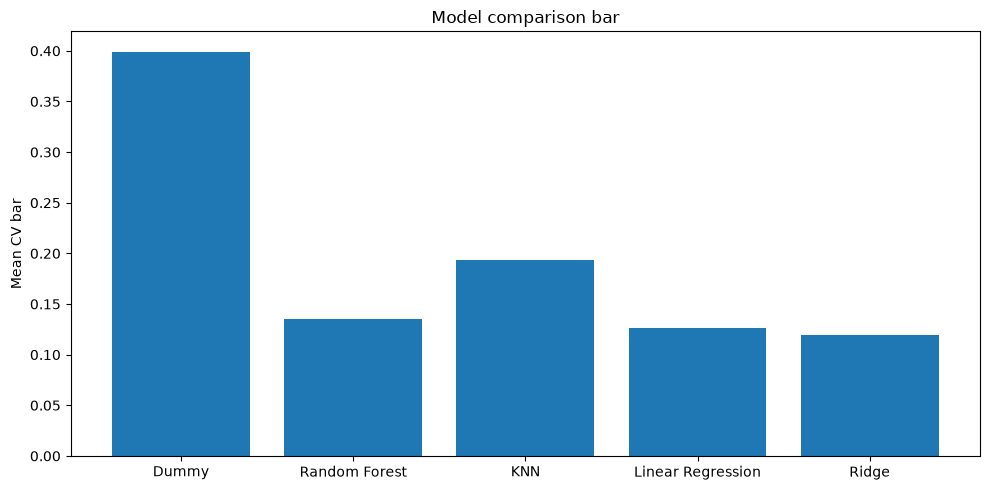

In [341]:
plt.figure(figsize=(10,5))
plt.bar(comparison['Model'],comparison['CV_mean'])
plt.ylabel('Mean CV bar')
plt.title('Model comparison bar')
plt.tight_layout()
plt.show()

In [340]:
from sklearn.model_selection import cross_val_predict

oof_predictions = cross_val_predict(
    ridge,
    X_train,
    y,
    cv=kf
)
oof_errors = y - oof_predictions
largest_errors = oof_errors.abs().sort_values(ascending=False)
largest_errors.head(10)

632     0.751382
462     0.674759
88      0.665724
1324    0.635705
968     0.601058
410     0.564381
30      0.539485
588     0.536139
1443    0.532885
970     0.526214
Name: SalePrice, dtype: float64

In [336]:
ridge.fit(X_train,y)
prediction = ridge.predict(test_processed)
prediction = np.exp(prediction)
submission = pd.DataFrame({'Id': test['Id'],'SalePrice': prediction})
submission.to_csv('../submissions/submission_ridge.csv', index=False)
